<a href="https://colab.research.google.com/github/baroonda/Actividad_4_DEAG/blob/main/Actividad_4_DEAG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!nvidia-smi
!pip install -q transformers datasets evaluate accelerate scikit-learn huggingface_hub

Sun Oct 11 18:39:25 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA RTX PRO 6000 Blac...    Off |   00000000:05:00.0 Off |                    0 |
| N/A   26C    P0             45W /  600W |       0MiB /  97887MiB |      0%      Default |
|                                         |                        |             Disabled |
+-----------------------------------------+-----

In [13]:
import os
import time
import numpy as np
import pandas as pd
from datasets import load_dataset

# Descargamos el dataset IMDB utilizando el namespace completo de stanfordnlp
dataset = load_dataset("stanfordnlp/imdb", split="test")

# Convertimos a DataFrame de pandas
df_raw = dataset.to_pandas()

# El dataset usa las etiquetas: 0 (negative), 1 (positive)
# Mapeamos los enteros a nuestras etiquetas estándar: NEG, POS
label_map = {0: "NEG", 1: "POS"}
df_raw["label"] = df_raw["label"].map(label_map)

# Seleccionamos las columnas y tomamos 150 ejemplos balanceados (75 de cada uno)
df_neg = df_raw[df_raw["label"] == "NEG"].sample(n=75, random_state=42)
df_pos = df_raw[df_raw["label"] == "POS"].sample(n=75, random_state=42)
df = pd.concat([df_neg, df_pos]).sample(frac=1, random_state=42).reset_index(drop=True)

# Crear la carpeta data/ y guardar el archivo
os.makedirs("data", exist_ok=True)
df.to_csv("data/reviews_dataset.csv", index=False)

print(f"Dataset IMDB en inglés creado exitosamente con {len(df)} filas.")
display(df.head())
print("Distribución de etiquetas:")
print(df["label"].value_counts())

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

...

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Dataset IMDB en inglés creado exitosamente con 150 filas.


,text,label
0,"Well, I have to admit that this movie brought ...",NEG
1,I was more entertained by watching my wife alm...,NEG
2,I own a Video store with hundreds of documenta...,POS
3,I never saw any of The League's work until ear...,POS
4,Ex-reporter Jacob Asch (Eric Roberts) is hired...,POS


Distribución de etiquetas:
label
NEG    75
POS    75
Name: count, dtype: int64


In [5]:
# Inspeccionar las columnas disponibles en el dataset
print("Columnas en el dataset:", dataset.column_names)

Columnas en el dataset: ['text', 'tweet_id', 'user_id']


In [14]:
import os
import time
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from transformers import pipeline

# Asegurar la carga de los datos salvados previamente para evitar NameError
data_path = "data/reviews_dataset.csv"
if not os.path.exists(data_path):
    raise FileNotFoundError(f"No se encontró el archivo {data_path}. Por favor ejecuta la celda anterior primero.")

eval_df = pd.read_csv(data_path)

# Modelos optimizados para idioma Inglés
models_to_test = {
    "distilbert_sst2": "distilbert-base-uncased-finetuned-sst-2-english",
    "twitter_roberta": "cardiffnlp/twitter-roberta-base-sentiment-latest",
    "multilingual_bert": "nlptown/bert-base-multilingual-uncased-sentiment"
}

results_summary = []

for model_name, model_id in models_to_test.items():
    print(f"\nEvaluando: {model_name}...")
    pipe = pipeline("text-classification", model=model_id, device=0)

    predictions = []
    latencies = []

    for text in eval_df["text"]:
        start_time = time.perf_counter()
        # Truncamos a 256 tokens para balancear velocidad y consistencia en textos largos de IMDB
        out = pipe(text[:1000], truncation=True, max_length=256)[0]
        latencies.append(time.perf_counter() - start_time)

        # Estandarización de etiquetas a POS, NEU, NEG
        raw_label = out["label"].upper()
        if "POS" in raw_label or raw_label in ["4 STARS", "5 STARS", "POSITIVE", "LABEL_2"]:
            norm_label = "POS"
        elif "NEG" in raw_label or raw_label in ["1 STAR", "2 STARS", "NEGATIVE", "LABEL_0"]:
            norm_label = "NEG"
        else:
            norm_label = "NEU"
        predictions.append(norm_label)

    acc = accuracy_score(eval_df["label"], predictions)
    prec, rec, f1, _ = precision_recall_fscore_support(eval_df["label"], predictions, average="weighted", zero_division=0)
    avg_latency = np.mean(latencies) * 1000 # ms

    results_summary.append({
        "Modelo": model_name,
        "HuggingFace ID": model_id,
        "Accuracy": round(acc, 4),
        "Precision": round(prec, 4),
        "Recall": round(rec, 4),
        "F1-Score": round(f1, 4),
        "Latencia Promedio (ms)": round(avg_latency, 2)
    })

# Guardar resultados en la carpeta results/
results_df = pd.DataFrame(results_summary)
os.makedirs("results", exist_ok=True)
results_df.to_csv("results/metricas_comparativas.csv", index=False)

print("\n--- Resultados Finales ---")
print(results_df.to_string(index=False))


Evaluando: distilbert_sst2...


Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset



Evaluando: twitter_roberta...


config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/39.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/872k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]


--- Resultados Finales ---
           Modelo                                   HuggingFace ID  Accuracy  Precision  Recall  F1-Score  Latencia Promedio (ms)
  distilbert_sst2  distilbert-base-uncased-finetuned-sst-2-english    0.8733     0.8788  0.8733    0.8729                   11.28
  twitter_roberta cardiffnlp/twitter-roberta-base-sentiment-latest    0.7000     0.8900  0.7000    0.7834                    4.65
multilingual_bert nlptown/bert-base-multilingual-uncased-sentiment    0.7533     0.9207  0.7533    0.8275                    4.08


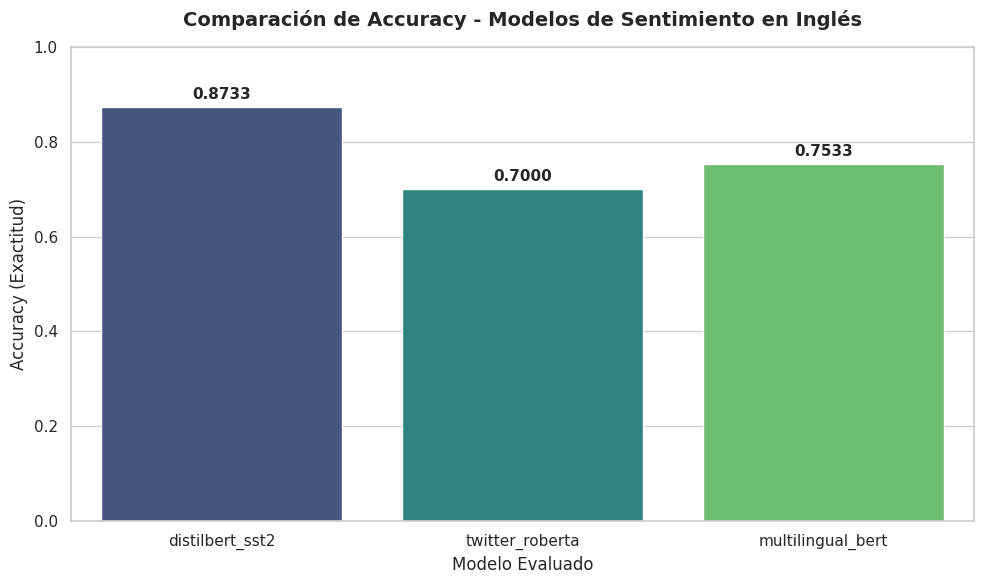

In [15]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuramos un estilo visual limpio
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 6))

# Creamos el gráfico de barras
ax = sns.barplot(
    x="Modelo",
    y="Accuracy",
    data=results_df,
    palette="viridis",
    hue="Modelo",
    legend=False
)

# Añadimos los valores exactos sobre cada barra para facilitar la lectura
for p in ax.patches:
    ax.annotate(f"{p.get_height():.4f}",
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='center',
                xytext=(0, 9),
                textcoords='offset points',
                fontsize=11,
                fontweight='bold')

# Personalización de títulos y etiquetas
plt.title("Comparación de Accuracy - Modelos de Sentimiento en Inglés", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Modelo Evaluado", fontsize=12)
plt.ylabel("Accuracy (Exactitud)", fontsize=12)
plt.ylim(0, 1.0)  # Límite de 0 a 100% para mantener la proporción

plt.tight_layout()
plt.show()

In [16]:
from google.colab import files

files.download("data/reviews_dataset.csv")
files.download("results/metricas_comparativas.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>